# Answers: visualising data with Seaborn

For our data visualisation exercises, let's take a look at a rather cute topic: penguins.

The [Palmer penguin dataset](https://www.kaggle.com/parulpandey/palmer-archipelago-antarctica-penguin-data)
contains measurements of penguins living in Antarctica, gathered by researchers at Palmer Station.
Each row represents one penguin.

| Variable | Definition |
|---|---|
| `species` | Penguin species: Adelie, Chinstrap or Gentoo |
| `culmen_length_mm` | Culmen (bill) length in millimetres |
| `culmen_depth_mm` | Culmen (bill) depth in millimetres |
| `flipper_length_mm` | Flipper length in millimetres |
| `body_mass_g` | Body mass in grams |
| `island` | Dream, Torgersen or Biscoe in the Palmer Archipelago |
| `sex` | Recorded sex of the penguin |

The culmen is the upper ridge of a bird's beak.

![Adelie, Chinstrap and Gentoo penguins and their bill measurements](penguins.jpg)

## Setup and loading

Run these supplied cells first. For each graph, add a clear title, axis labels with units,
and a useful legend when using colour. Explain what you notice.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
penguins_df = pd.read_csv("penguins_size.csv")

# Some penguins do not have a full set of measurements (recorded as NaN).
# For these exercises, keep penguins with complete records.
penguins_df = penguins_df.dropna()

# One record has "." instead of a valid sex: remove it too.
penguins_df = penguins_df.loc[penguins_df["sex"] != "."].copy()
penguins_df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


## 1. How heavy are the different penguin species?

Make a bar chart showing the **mean body mass for each species**.
Use `sns.barplot()` with species on the x-axis and body mass on the y-axis.
Seaborn calculates the mean for each species from the individual penguins.
Use `errorbar=None` for this first chart, and start the mass axis at zero.

Which species is heaviest on average? Does the chart show how much individual penguins vary?

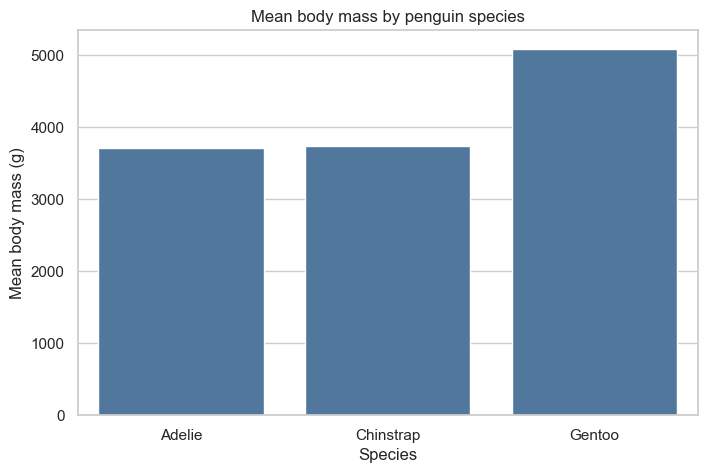

species
Adelie       3706.2
Chinstrap    3733.1
Gentoo       5092.4
Name: body_mass_g, dtype: float64

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=penguins_df, x="species", y="body_mass_g",
            color="#4477AA", errorbar=None, ax=ax)
ax.set(title="Mean body mass by penguin species", xlabel="Species",
       ylabel="Mean body mass (g)", ylim=(0, None))
plt.show()

penguins_df.groupby("species")["body_mass_g"].mean().round(1)

**Example interpretation:** Gentoo penguins are heaviest on average (about 5,092 g), compared with about
3,706 g for Adelie and 3,733 g for Chinstrap. Each bar summarises a mean; it does not
show the spread of individual measurements.

## 2. Do longer flippers go with heavier penguins?

Make a scatter plot of **flipper length versus body mass** using `sns.scatterplot()`.
Put flipper length on x, body mass on y, and use `hue="species"` to give each species a different colour.
Try `alpha=0.7` to help with overlapping points.

Describe the relationship and the species clusters. As an optional extension, try bill length
or bill depth instead of flipper length, or make a box plot of flipper length or body mass by species.

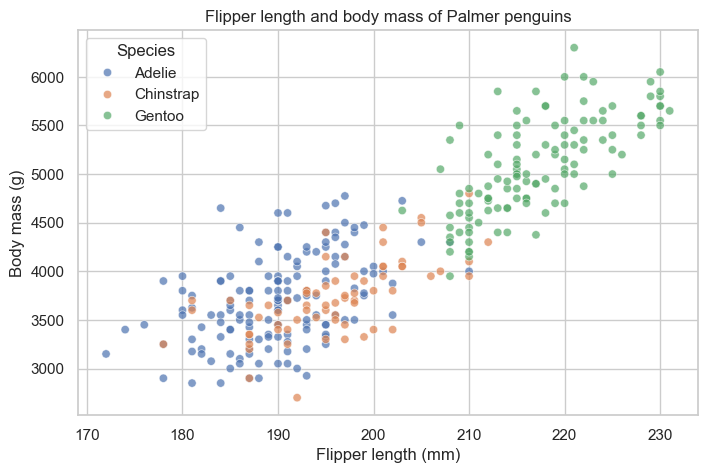

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=penguins_df, x="flipper_length_mm", y="body_mass_g",
                hue="species", alpha=0.7, ax=ax)
ax.set(title="Flipper length and body mass of Palmer penguins",
       xlabel="Flipper length (mm)", ylabel="Body mass (g)")
ax.legend(title="Species")
plt.show()

**Example interpretation:** Longer flippers generally go with greater body mass. Gentoo penguins form a
cluster with longer flippers and heavier bodies, while Adelie and Chinstrap overlap more.
There is still variation within each species; the overall relationship partly reflects species differences.

## From penguins to names: one colour per region

Now use colour to compare how a name's popularity changes over time.
We have Scotland and four US Census regions: Midwest, Northeast, South and West.
Scotland is our UK comparison here; these data do not represent the whole UK.

Run the loading cell below. These are the same files used in the instructor notebook.

In [5]:
scotland_names_df = pd.read_csv("../week_3/scotland_babynames.csv")
usa_names_df = pd.read_csv("../week_3/us_babynames_by_region.csv")
display(scotland_names_df.head())
display(usa_names_df.head())

,Sex,Year,Name,Count,Rank
0,M,1974,Aaron,17,139
1,M,1974,Abdul,5,248
2,M,1974,Adam,75,78
3,M,1974,Adrian,46,92
4,M,1974,Aftab,3,297


,Region,Sex,Year,Name,Count
0,Midwest,F,1910,Mary,5024
1,Midwest,F,1910,Helen,3747
2,Midwest,F,1910,Dorothy,2677
3,Midwest,F,1910,Margaret,2502
4,Midwest,F,1910,Ruth,2377


## 3. Add Scotland as another region

1. Make a copy of `scotland_names_df` called `scotland_region_df`.
2. Give it a new `Region` column containing `"Scotland"`.
3. Keep the common columns `Region`, `Sex`, `Year`, `Name` and `Count` in both tables.
4. Stack their rows into `all_names_df` using `pd.concat(..., ignore_index=True)`.
5. Keep all available years and display the region names.

The US data cover 1910–2025, while Scotland covers 1974–2025. Let each series
show its full history; Scotland's later start reflects the coverage of the file.

**Hint:** `pd.concat([first_df, second_df], ignore_index=True)` adds rows.
Use this to bring Scotland into the regional table. A `merge()` joins matching columns;
we will use it next to attach totals.

In [6]:
scotland_region_df = scotland_names_df.copy()
scotland_region_df["Region"] = "Scotland"
columns = ["Region", "Sex", "Year", "Name", "Count"]
all_names_df = pd.concat(
    [usa_names_df[columns], scotland_region_df[columns]], ignore_index=True
)

display(all_names_df.head())
print(all_names_df["Region"].unique())

,Region,Sex,Year,Name,Count
0,Midwest,F,1910,Mary,5024
1,Midwest,F,1910,Helen,3747
2,Midwest,F,1910,Dorothy,2677
3,Midwest,F,1910,Margaret,2502
4,Midwest,F,1910,Ruth,2377


['Midwest' 'Northeast' 'South' 'West' 'Scotland']


## 4. Make the comparisons fair

Regions have different population sizes. Following the instructor notebook, calculate
`CountPer1000`: babies with a given name per 1,000 recorded names **of the same sex, in the same year and region**.

1. Group `all_names_df` by `Year`, `Region` and `Sex`; sum `Count` and rename the result `TotalCount`.
2. Merge these totals onto `all_names_df` using all three grouping columns.
   Store the result as `names_rates_df`.
3. Calculate `CountPer1000 = 1000 * Count / TotalCount`.
4. Inspect the result before plotting.

Calculate totals from **all names**, before selecting Taylor or any other name.
The rates refer to the records in these files: published names data can omit rare names,
so these are not exact rates for all births. An absent row is not necessarily a zero.

In [7]:
totals_by_region_df = (
    all_names_df.groupby(["Year", "Region", "Sex"], as_index=False)["Count"]
    .sum()
    .rename(columns={"Count": "TotalCount"})
)
names_rates_df = all_names_df.merge(
    totals_by_region_df, on=["Year", "Region", "Sex"], validate="many_to_one"
)
names_rates_df["CountPer1000"] = (
    1000 * names_rates_df["Count"] / names_rates_df["TotalCount"]
)
names_rates_df.head()

,Region,Sex,Year,Name,Count,TotalCount,CountPer1000
0,Midwest,F,1910,Mary,5024,90912,55.262232
1,Midwest,F,1910,Helen,3747,90912,41.215681
2,Midwest,F,1910,Dorothy,2677,90912,29.446058
3,Midwest,F,1910,Margaret,2502,90912,27.521119
4,Midwest,F,1910,Ruth,2377,90912,26.146163


## Keep colours consistent

Run this supplied cell and use `palette=region_colours` for every regional graph.
That way, Scotland keeps the same colour when we switch names.

In [8]:
region_colours = {
    "Scotland": "#0756EA",
    "Midwest": "#4B7101",
    "Northeast": "#D55E00",
    "South": "#2ED7AA",
    "West": "#D6338D",
}

## 5. Taylor: do names become popular everywhere at once?

Select `Name == "Taylor"` and `Sex == "F"` into `taylor_girls_df`, keeping all available years.
Make a line plot with year on x, `CountPer1000` on y and **`hue="Region"`**.
Use `palette=region_colours` and `estimator=None` so each region has its own line.

- Where and when is Taylor most popular? Does Scotland peak at the same time as the US regions?
- Do the US regions agree with one another?
- Why would raw counts make this comparison harder?

Remember to select a sex; otherwise a region can have two values per year.
Some early years have no published observation for a name. These are not necessarily zeros.

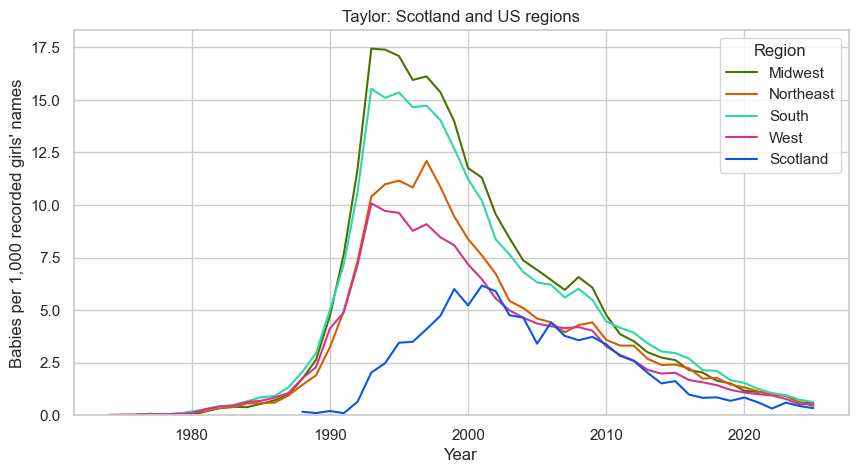

,Region,Year,CountPer1000
183097,Midwest,1993,17.44
549788,Northeast,1997,12.09
1659535,Scotland,2001,6.17
959547,South,1993,15.53
1403751,West,1993,10.08


In [9]:
select_name = names_rates_df["Name"] == "Taylor"
select_sex = names_rates_df["Sex"] == "F"

taylor_girls_df = names_rates_df.loc[select_name & select_sex].copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=taylor_girls_df, x="Year", y="CountPer1000", hue="Region",
             palette=region_colours, estimator=None, ax=ax)
ax.set(title="Taylor: Scotland and US regions",
       xlabel="Year", ylabel="Babies per 1,000 recorded girls' names",
       ylim=(0, None))
ax.legend(title="Region")
plt.show()

# Inspect the highest observed rate in each region across all available years.
peak_rows = taylor_girls_df.groupby("Region")["CountPer1000"].idxmax()
display(taylor_girls_df.loc[peak_rows, ["Region", "Year", "CountPer1000"]].round(2))

**Example interpretation:** The Midwest, South and West peak in 1993,
while the Northeast peaks in 1997. Scotland peaks later, in 2001, at about 6.17 per 1,000
recorded girls' names. The Midwest peak is about 17.44. All five rates are much lower by 2025.
Rates account for differences in the numbers of recorded girls' names; raw counts do not.
Timing alone does not explain why a name became popular.

## 6. Taylor for boys

Repeat the graph for `Sex == "M"`, keeping all available years and the same region colours.
To compare boys and girls fairly, give **both Taylor plots a y-axis from 0 to 20**
(using `ax.set_ylim(0, 20)` before `plt.show()`).

How do the peak years and rates differ? Is Taylor relatively more popular among boys
or girls in Scotland by 2025? Remember that each sex has its own denominator.

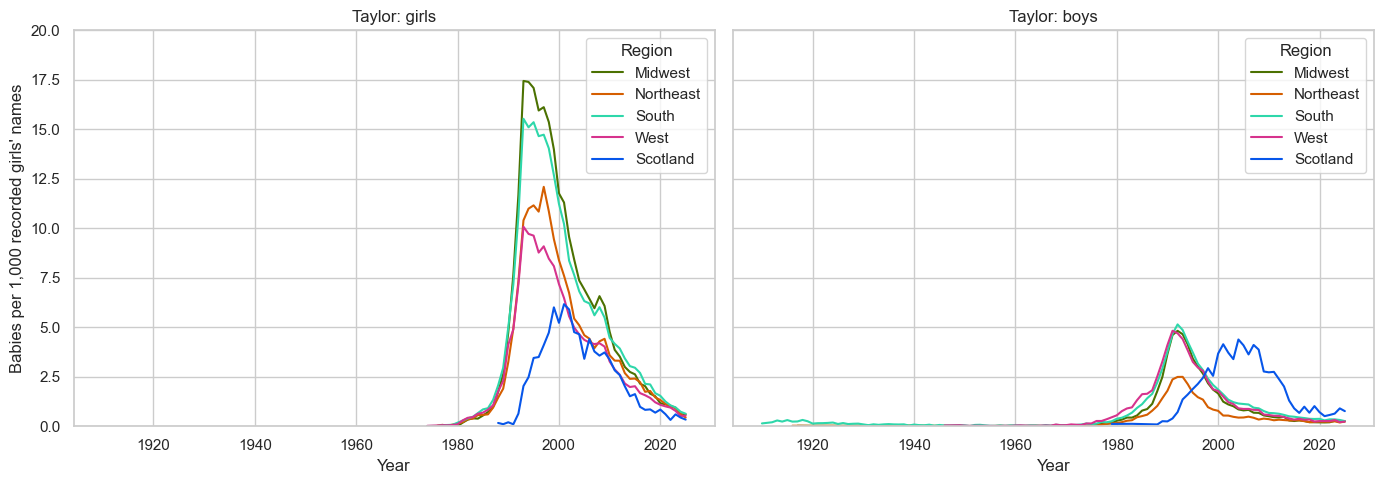

In [10]:
# Redraw both on matching axes so their heights can be compared directly.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for sex, label, ax in zip(["F", "M"], ["Girls", "Boys"], axes):
    selected_df = names_rates_df.loc[
        (names_rates_df["Name"] == "Taylor")
        & (names_rates_df["Sex"] == sex)
    ]
    sns.lineplot(data=selected_df, x="Year", y="CountPer1000", hue="Region",
                 palette=region_colours, estimator=None, ax=ax)
    ax.set(title=f"Taylor: {label.lower()}", xlabel="Year",
           ylabel=f"Babies per 1,000 recorded {label.lower()}' names",
           ylim=(0, 20))
    ax.legend(title="Region")
fig.tight_layout()
plt.show()

**Example interpretation:** US boys' rates peak around 1991–1993, and Scotland's in 2004 (about 4.38 per 1,000).
Girls reach higher peak rates in every region. By 2025, however, Scotland's rate is about
0.76 for boys and 0.34 for girls. These compare popularity within each sex, not the proportion
of all Taylors who are boys or girls.

## 7. Choose another pattern: Isla or Jacob

Choose **Isla** (`Sex == "F"`) or **Jacob** (`Sex == "M"`) and plot all available years.
Use the same regional colours, clear labels and a zero baseline.

For either of these names:
- Is its popularity similar in Scotland and the US regions? Are the lines moving in the same direction?
- Do the regions reach their peaks at similar times? Where is the peak highest?

Explore the full history, including the earlier US records. Each series can start at a different
time because of dataset coverage or missing observations for that name.

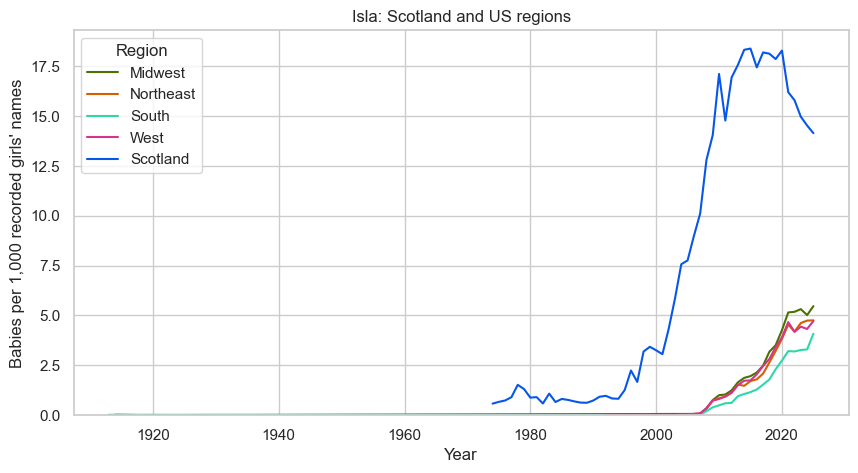

,Region,Year,CountPer1000
324055,Midwest,2025,5.47
692295,Northeast,2025,4.76
1682818,Scotland,2015,18.38
1176741,South,2025,4.09
1621635,West,2025,4.72


In [11]:
select_name = names_rates_df["Name"] == "Isla"
select_sex = names_rates_df["Sex"] == "F"
isla_df = names_rates_df.loc[select_name & select_sex ].copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=isla_df, x="Year", y="CountPer1000", hue="Region",
             palette=region_colours, estimator=None, ax=ax)
ax.set(title="Isla: Scotland and US regions",
       xlabel="Year", ylabel="Babies per 1,000 recorded girls' names",
       ylim=(0, None))
ax.legend(title="Region")
plt.show()

# Inspect the highest observed rate in each region across all available years.
peak_rows = isla_df.groupby("Region")["CountPer1000"].idxmax()
display(isla_df.loc[peak_rows, ["Region", "Year", "CountPer1000"]].round(2))

**Example interpretation:** Isla's Scottish rate peaks in 2015 at about 18.38 per 1,000,
then falls to 14.14 in 2025. All four US regions reach their highest recorded rates in 2025
(about 4.09–5.47). The full history shows that Isla was recorded in Scotland well before
its recent US rise, and it remains much more popular in Scotland in 2025.

**Alternative solution: Jacob**

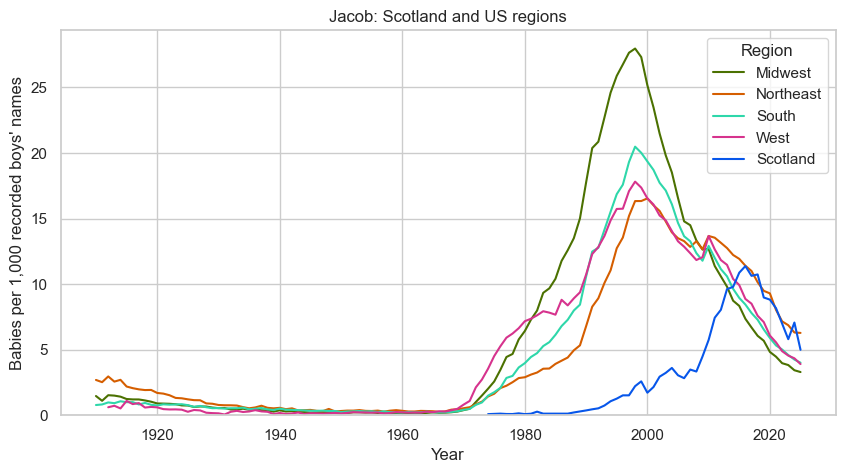

,Region,Year,CountPer1000
204191,Midwest,1998,27.96
566228,Northeast,2000,16.53
1683789,Scotland,2016,11.37
988938,South,1998,20.48
1438711,West,1998,17.81


In [12]:
select_name = names_rates_df["Name"] == "Jacob"
select_sex = names_rates_df["Sex"] == "M"
jacob_df = names_rates_df.loc[select_name & select_sex ].copy()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=jacob_df, x="Year", y="CountPer1000", hue="Region",
             palette=region_colours, estimator=None, ax=ax)
ax.set(title="Jacob: Scotland and US regions",
       xlabel="Year", ylabel="Babies per 1,000 recorded boys' names",
       ylim=(0, None))
ax.legend(title="Region")
plt.show()

# Inspect the highest observed rate in each region across all available years.
peak_rows = jacob_df.groupby("Region")["CountPer1000"].idxmax()
display(jacob_df.loc[peak_rows, ["Region", "Year", "CountPer1000"]].round(2))

Jacob peaks in 1998 in the Midwest, South and West, and in 2000 in the Northeast.
Scotland peaks much later, in 2016. The Midwest has the highest peak, about 27.96 per 1,000
recorded boys' names, compared with Scotland's 11.37. The longer US history shows the rise
leading up to those peaks, and all five regions have lower rates by 2025.

## 8. Your own name

Finish with your own first name, or another name you are curious about. Choose a sex and
compare Scotland with the US regions. Reuse the preparation and colours above.

First inspect which years and regions contain your chosen name. If observations are sparse,
use a scatter plot to show the available points rather than connecting across missing years.
Do not turn missing records into zeros. If no rows match, check the spelling or try another name.

Give your graph a title and write two or three sentences about what you found.
You could also revisit George from the instructor notebook, or investigate Jennifer's earlier
popularity. Use the full available history when exploring these names.

,min,max,nunique
Region,,,
Midwest,1912,2025,111
Northeast,1912,2025,114
Scotland,1974,2025,51
South,1910,2025,102
West,1914,2025,93


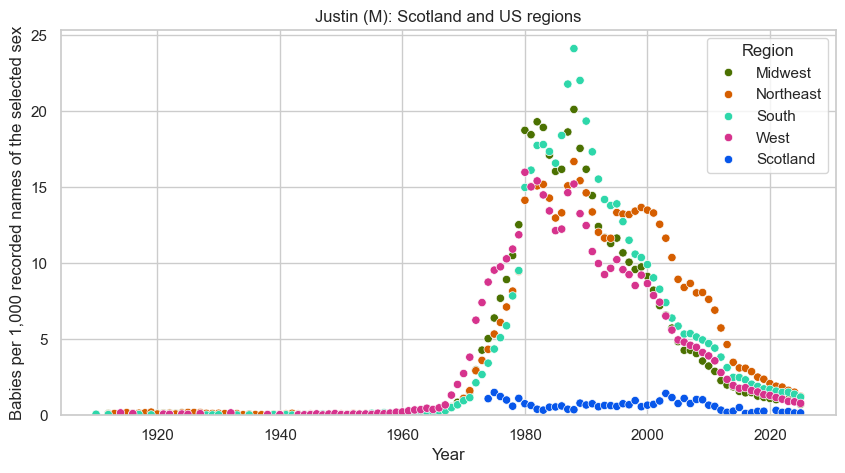

In [13]:
# Replace these values with your own choice. 
chosen_name = "Justin"
chosen_sex = "M"
my_name_df = names_rates_df.loc[
    (names_rates_df["Name"] == chosen_name)
    & (names_rates_df["Sex"] == chosen_sex)
].copy()

if my_name_df.empty:
    print("No matching records: check the spelling or try another name.")
else:
    display(my_name_df.groupby("Region")["Year"].agg(["min", "max", "nunique"]))
    # Points work for both complete and sparse records without joining missing years.
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.scatterplot(data=my_name_df, x="Year", y="CountPer1000", hue="Region",
                    palette=region_colours, ax=ax)
    ax.set(title=f"{chosen_name} ({chosen_sex}): Scotland and US regions",
           xlabel="Year", ylabel="Babies per 1,000 recorded names of the selected sex",
           ylim=(0, None))
    ax.legend(title="Region")
    plt.show()

**Example interpretation:** Answers depend on the name. For Justin (M), the Midwest,
Northeast and South peak in 1988, while the West peaks in 1980. Scotland's highest recorded
rate is in 1975, at about 1.50 per 1,000, far below the US regional peaks (about 15.98–24.11).
Describe your own result using specific years or rates, and say if missing observations
limit the comparison.